In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/alaakhaled/conll003-englishversion/valid.txt
/kaggle/input/datasets/alaakhaled/conll003-englishversion/metadata
/kaggle/input/datasets/alaakhaled/conll003-englishversion/test.txt
/kaggle/input/datasets/alaakhaled/conll003-englishversion/train.txt


In [ ]:
import os
import re
import copy
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

from collections import Counter

from sklearn.metrics import confusion_matrix

from seqeval.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    TrainingArguments,
    Trainer,
    DataCollatorForTokenClassification,
    EarlyStoppingCallback
)

from datasets import Dataset as HFDataset

from torchcrf import CRF

import gradio as gr

In [3]:
DATA_PATH = "/kaggle/input/datasets/alaakhaled/conll003-englishversion"

train_path = os.path.join(DATA_PATH, "train.txt")
valid_path = os.path.join(DATA_PATH, "valid.txt")
test_path = os.path.join(DATA_PATH, "test.txt")

for name, path in [
    ("Train", train_path),
    ("Validation", valid_path),
    ("Test", test_path)
]:
    with open(path, "r", encoding="utf-8") as file:
        lines = file.readlines()

    print(f"{name}: {len(lines)} lines")

Train: 219554 lines
Validation: 55044 lines
Test: 50350 lines


In [4]:
with open(train_path, "r", encoding="utf-8") as file:
    for i in range(30):
        print(file.readline().rstrip())

-DOCSTART- -X- -X- O

EU NNP B-NP B-ORG
rejects VBZ B-VP O
German JJ B-NP B-MISC
call NN I-NP O
to TO B-VP O
boycott VB I-VP O
British JJ B-NP B-MISC
lamb NN I-NP O
. . O O

Peter NNP B-NP B-PER
Blackburn NNP I-NP I-PER

BRUSSELS NNP B-NP B-LOC
1996-08-22 CD I-NP O

The DT B-NP O
European NNP I-NP B-ORG
Commission NNP I-NP I-ORG
said VBD B-VP O
on IN B-PP O
Thursday NNP B-NP O
it PRP B-NP O
disagreed VBD B-VP O
with IN B-PP O
German JJ B-NP B-MISC
advice NN I-NP O
to TO B-PP O


In [7]:
with open(train_path, "r", encoding="utf-8") as file:
    for i, line in enumerate(file):
        if line.strip():
            print(line.rstrip())
        else:
            print("--- Sentence Boundary ---")

        if i >= 29:
            break

-DOCSTART- -X- -X- O
--- Sentence Boundary ---
EU NNP B-NP B-ORG
rejects VBZ B-VP O
German JJ B-NP B-MISC
call NN I-NP O
to TO B-VP O
boycott VB I-VP O
British JJ B-NP B-MISC
lamb NN I-NP O
. . O O
--- Sentence Boundary ---
Peter NNP B-NP B-PER
Blackburn NNP I-NP I-PER
--- Sentence Boundary ---
BRUSSELS NNP B-NP B-LOC
1996-08-22 CD I-NP O
--- Sentence Boundary ---
The DT B-NP O
European NNP I-NP B-ORG
Commission NNP I-NP I-ORG
said VBD B-VP O
on IN B-PP O
Thursday NNP B-NP O
it PRP B-NP O
disagreed VBD B-VP O
with IN B-PP O
German JJ B-NP B-MISC
advice NN I-NP O
to TO B-PP O


In [6]:
for name, path in [
    ("Train", train_path),
    ("Validation", valid_path),
    ("Test", test_path)
]:
    with open(path, "r", encoding="utf-8") as file:
        content = file.read()

    sentences = [s for s in content.strip().split("\n\n") if s.strip()]

    print(f"{name}:")
    print("Sentences:", len(sentences))
    print("Characters:", len(content))
    print("-" * 30)

Train:
Sentences: 14987
Characters: 3283420
------------------------------
Validation:
Sentences: 3466
Characters: 827443
------------------------------
Test:
Sentences: 3684
Characters: 748095
------------------------------


In [8]:
with open(train_path, "r", encoding="utf-8") as file:
    for i, line in enumerate(file):
        if line.strip():
            print(line.rstrip().split())

        if i >= 19:
            break

['-DOCSTART-', '-X-', '-X-', 'O']
['EU', 'NNP', 'B-NP', 'B-ORG']
['rejects', 'VBZ', 'B-VP', 'O']
['German', 'JJ', 'B-NP', 'B-MISC']
['call', 'NN', 'I-NP', 'O']
['to', 'TO', 'B-VP', 'O']
['boycott', 'VB', 'I-VP', 'O']
['British', 'JJ', 'B-NP', 'B-MISC']
['lamb', 'NN', 'I-NP', 'O']
['.', '.', 'O', 'O']
['Peter', 'NNP', 'B-NP', 'B-PER']
['Blackburn', 'NNP', 'I-NP', 'I-PER']
['BRUSSELS', 'NNP', 'B-NP', 'B-LOC']
['1996-08-22', 'CD', 'I-NP', 'O']
['The', 'DT', 'B-NP', 'O']
['European', 'NNP', 'I-NP', 'B-ORG']


In [9]:
def load_conll_data(file_path):
    sentences = []
    tokens = []
    tags = []

    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()

            if not line:
                if tokens:
                    sentences.append({
                        "tokens": tokens,
                        "tags": tags
                    })
                    tokens = []
                    tags = []
                continue

            parts = line.split()

            if len(parts) != 4:
                continue

            token, pos, chunk, ner = parts

            if token == "-DOCSTART-":
                continue

            tokens.append(token)
            tags.append(ner)

    if tokens:
        sentences.append({
            "tokens": tokens,
            "tags": tags
        })

    return sentences


train_data = load_conll_data(train_path)
valid_data = load_conll_data(valid_path)
test_data = load_conll_data(test_path)

print("Train:", len(train_data))
print("Validation:", len(valid_data))
print("Test:", len(test_data))

Train: 14041
Validation: 3250
Test: 3453


In [10]:
print("Tokens:")
print(train_data[0]["tokens"])

print("\nNER Tags:")
print(train_data[0]["tags"])

Tokens:
['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']

NER Tags:
['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']


In [11]:
all_tags = []

for sentence in train_data:
    all_tags.extend(sentence["tags"])

tag_counts = Counter(all_tags)

for tag, count in sorted(tag_counts.items()):
    print(f"{tag}: {count}")

B-LOC: 7140
B-MISC: 3438
B-ORG: 6321
B-PER: 6600
I-LOC: 1157
I-MISC: 1155
I-ORG: 3704
I-PER: 4528
O: 169578


In [12]:
entity_counts = Counter()
sentence_lengths = []

for sentence in train_data:
    tokens = sentence["tokens"]
    tags = sentence["tags"]

    sentence_lengths.append(len(tokens))

    for tag in tags:
        if tag.startswith("B-"):
            entity_counts[tag[2:]] += 1

print("Entity Counts:")

for entity, count in entity_counts.items():
    print(f"{entity}: {count}")

print("\nSentence Statistics:")
print("Total Sentences:", len(train_data))
print("Average Length:", sum(sentence_lengths) / len(sentence_lengths))
print("Maximum Length:", max(sentence_lengths))
print("Minimum Length:", min(sentence_lengths))

Entity Counts:
ORG: 6321
MISC: 3438
PER: 6600
LOC: 7140

Sentence Statistics:
Total Sentences: 14041
Average Length: 14.501887329962253
Maximum Length: 113
Minimum Length: 1


# CoNLL-2003 Dataset Analysis

### Entity Distribution

Entity Type,Description,Count,Percentage
PER,Person,"6,600",28.09%
ORG,Organization,"6,321",26.90%
LOC,Location,"7,140",30.38%
MISC,Miscellaneous,"3,438",14.63%


### Dataset Statistics

Metric,Value
Total Sentences,"14,041"
Total Tokens,"203,621"
Total Named Entities,"23,499"
Average Sentence Length,14.50 tokens
Maximum Sentence Length,113 tokens
Minimum Sentence Length,1 token


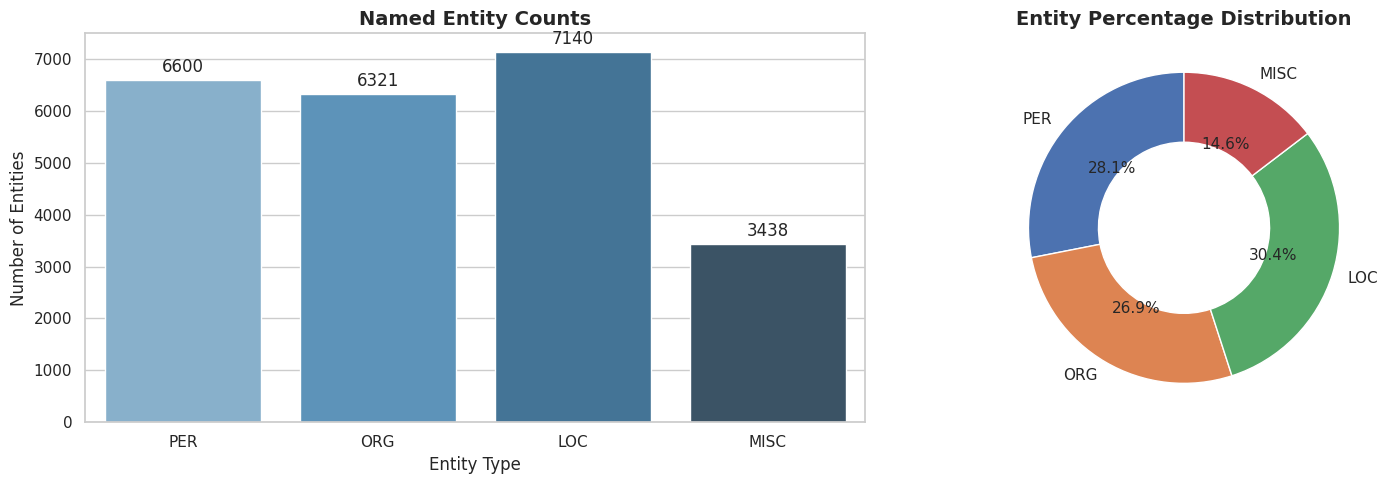

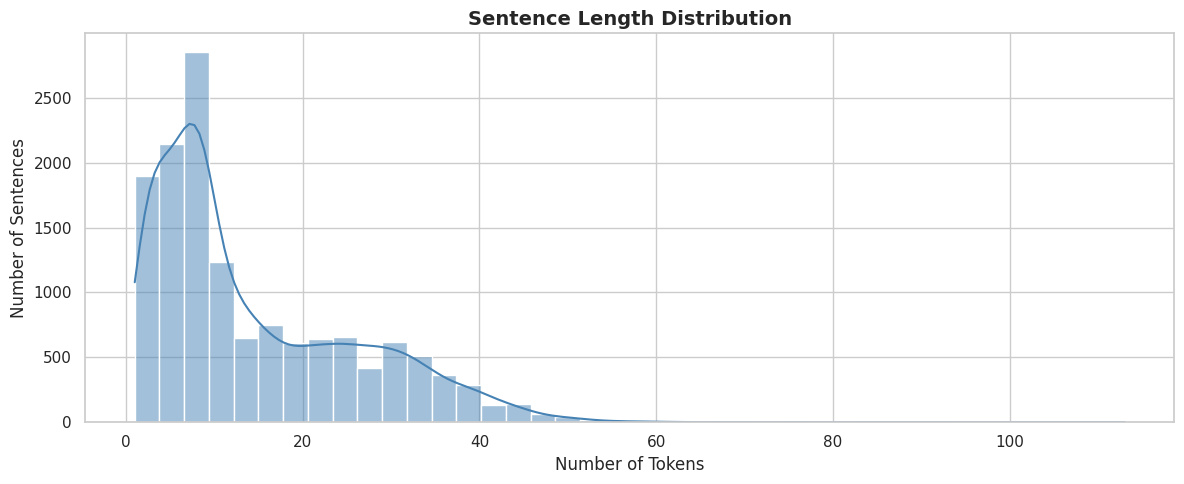

In [13]:
sns.set_theme(style="whitegrid")

entity_counts = Counter()
tag_counts = Counter()
sentence_lengths = []

for sentence in train_data:
    sentence_lengths.append(len(sentence["tokens"]))

    for tag in sentence["tags"]:
        tag_counts[tag] += 1

        if tag.startswith("B-"):
            entity_counts[tag[2:]] += 1

entity_df = pd.DataFrame({
    "Entity Type": ["PER", "ORG", "LOC", "MISC"],
    "Description": ["Person", "Organization", "Location", "Miscellaneous"],
    "Count": [
        entity_counts["PER"],
        entity_counts["ORG"],
        entity_counts["LOC"],
        entity_counts["MISC"]
    ]
})

entity_df["Percentage"] = (
    entity_df["Count"] / entity_df["Count"].sum() * 100
).round(2)

total_entities = entity_df["Count"].sum()

stats_df = pd.DataFrame({
    "Metric": [
        "Total Sentences",
        "Total Tokens",
        "Total Named Entities",
        "Average Sentence Length",
        "Maximum Sentence Length",
        "Minimum Sentence Length"
    ],
    "Value": [
        f"{len(train_data):,}",
        f"{sum(tag_counts.values()):,}",
        f"{total_entities:,}",
        f"{sum(sentence_lengths) / len(sentence_lengths):.2f} tokens",
        f"{max(sentence_lengths)} tokens",
        f"{min(sentence_lengths)} token"
    ]
})

display(Markdown("# CoNLL-2003 Dataset Analysis"))
display(Markdown("### Entity Distribution"))

display(
    entity_df.style
    .format({"Count": "{:,.0f}", "Percentage": "{:.2f}%"})
    .background_gradient(subset=["Count"], cmap="Blues")
    .hide(axis="index")
)

display(Markdown("### Dataset Statistics"))

display(
    stats_df.style
    .hide(axis="index")
    .set_properties(**{"text-align": "left"})
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    data=entity_df,
    x="Entity Type",
    y="Count",
    hue="Entity Type",
    palette="Blues_d",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Named Entity Counts", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Entity Type")
axes[0].set_ylabel("Number of Entities")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

axes[1].pie(
    entity_df["Count"],
    labels=entity_df["Entity Type"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.45, "edgecolor": "white"},
    textprops={"fontsize": 11}
)

axes[1].set_title("Entity Percentage Distribution", fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))

sns.histplot(
    sentence_lengths,
    bins=40,
    kde=True,
    color="steelblue"
)

plt.title("Sentence Length Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Sentences")

plt.tight_layout()
plt.show()

In [14]:
word_counter = Counter()

for sentence in train_data:
    word_counter.update(sentence["tokens"])

word2idx = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in word_counter.items():
    if word not in word2idx:
        word2idx[word] = len(word2idx)

all_labels = sorted({
    tag
    for sentence in train_data
    for tag in sentence["tags"]
})

tag2idx = {
    tag: idx
    for idx, tag in enumerate(all_labels)
}

idx2tag = {
    idx: tag
    for tag, idx in tag2idx.items()
}

print("Vocabulary Size:", len(word2idx))
print("Number of NER Labels:", len(tag2idx))

print("\nNER Label Mapping:")
display(pd.DataFrame({
    "Label": list(tag2idx.keys()),
    "ID": list(tag2idx.values())
}))

Vocabulary Size: 23625
Number of NER Labels: 9

NER Label Mapping:


,Label,ID
0,B-LOC,0
1,B-MISC,1
2,B-ORG,2
3,B-PER,3
4,I-LOC,4
5,I-MISC,5
6,I-ORG,6
7,I-PER,7
8,O,8


In [15]:
def calculate_oov(data, vocabulary):
    total_tokens = 0
    unknown_tokens = 0

    for sentence in data:
        for token in sentence["tokens"]:
            total_tokens += 1

            if token not in vocabulary:
                unknown_tokens += 1

    return {
        "Total Tokens": total_tokens,
        "OOV Tokens": unknown_tokens,
        "OOV Percentage": round(
            unknown_tokens / total_tokens * 100, 2
        )
    }


oov_results = pd.DataFrame([
    {
        "Dataset": name,
        **calculate_oov(data, word2idx)
    }
    for name, data in [
        ("Train", train_data),
        ("Validation", valid_data),
        ("Test", test_data)
    ]
])

display(
    oov_results.style
    .format({
        "Total Tokens": "{:,}",
        "OOV Tokens": "{:,}",
        "OOV Percentage": "{:.2f}%"
    })
    .background_gradient(subset=["OOV Percentage"], cmap="Reds")
    .hide(axis="index")
)

Dataset,Total Tokens,OOV Tokens,OOV Percentage
Train,"203,621",0,0.00%
Validation,"51,362","4,293",8.36%
Test,"46,435","5,656",12.18%


### Sentence Length Percentiles

Percentile,Sentence Length
50%,10
75%,22
90%,32
95%,37
99%,46
100%,113


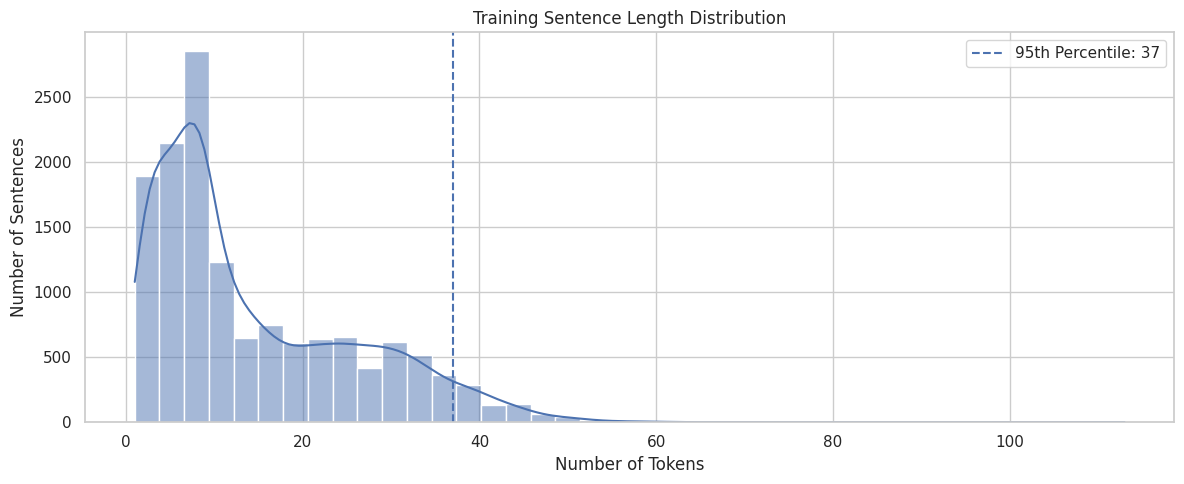

In [16]:
lengths = np.array([
    len(sentence["tokens"])
    for sentence in train_data
])

percentiles = [50, 75, 90, 95, 99, 100]

length_df = pd.DataFrame({
    "Percentile": [f"{p}%" for p in percentiles],
    "Sentence Length": [
        int(np.percentile(lengths, p))
        for p in percentiles
    ]
})

display(Markdown("### Sentence Length Percentiles"))
display(length_df.style.hide(axis="index"))

plt.figure(figsize=(12, 5))

sns.histplot(lengths, bins=40, kde=True)

plt.axvline(
    np.percentile(lengths, 95),
    linestyle="--",
    label=f"95th Percentile: {np.percentile(lengths, 95):.0f}"
)

plt.title("Training Sentence Length Distribution")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Sentences")
plt.legend()

plt.tight_layout()
plt.show()

In [36]:
GLOVE_PATH = "/kaggle/working/glove.6B.100d.txt"

url = "https://huggingface.co/kcz358/glove/resolve/main/glove.6B/glove.6B.100d.txt"

response = requests.get(url, stream=True, timeout=60)
response.raise_for_status()

with open(GLOVE_PATH, "wb") as file:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            file.write(chunk)

print("Download completed!")

Download completed!


In [37]:
print("Current Directory:", os.getcwd())
print("Files:", os.listdir("/kaggle/working"))

embedding_dim = 100
vocab_words = set(word2idx.keys())
lower_vocab = {word.lower() for word in vocab_words}

embedding_index = {}

with open("glove.6B.100d.txt", "r", encoding="utf-8") as file:
    for line in file:
        values = line.split()
        word = values[0]

        if word in vocab_words or word.lower() in lower_vocab:
            vector = np.asarray(values[1:], dtype="float32")

            if len(vector) == embedding_dim:
                embedding_index[word] = vector

embedding_matrix = np.random.normal(
    0,
    0.6,
    (len(word2idx), embedding_dim)
).astype("float32")

embedding_matrix[word2idx["<PAD>"]] = np.zeros(embedding_dim)

matched_words = 0

for word, idx in word2idx.items():
    if word in embedding_index:
        embedding_matrix[idx] = embedding_index[word]
        matched_words += 1
    elif word.lower() in embedding_index:
        embedding_matrix[idx] = embedding_index[word.lower()]
        matched_words += 1

coverage = matched_words / len(word2idx) * 100

print("Embedding Matrix Shape:", embedding_matrix.shape)
print("Matched Words:", matched_words)
print("Vocabulary Size:", len(word2idx))
print(f"GloVe Coverage: {coverage:.2f}%")

Current Directory: /kaggle/working
Files: ['glove.6B.zip', 'glove.6B.100d.txt', '.virtual_documents']
Embedding Matrix Shape: (23625, 100)
Matched Words: 21009
Vocabulary Size: 23625
GloVe Coverage: 88.93%


In [38]:
MAX_LEN = int(np.percentile(
    [len(s["tokens"]) for s in train_data],
    95
))

def truncation_rate(data, max_len):
    truncated = sum(
        len(s["tokens"]) > max_len
        for s in data
    )

    return truncated / len(data) * 100

length_results = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Sentences": [
        len(train_data),
        len(valid_data),
        len(test_data)
    ],
    "Truncation Rate": [
        truncation_rate(train_data, MAX_LEN),
        truncation_rate(valid_data, MAX_LEN),
        truncation_rate(test_data, MAX_LEN)
    ]
})

print("Selected MAX_LEN:", MAX_LEN)

display(
    length_results.style
    .format({"Truncation Rate": "{:.2f}%"})
    .hide(axis="index")
)

Selected MAX_LEN: 37


Dataset,Sentences,Truncation Rate
Train,14041,5.00%
Validation,3250,6.06%
Test,3453,4.43%


In [39]:
def prepare_dataset(data, max_len):
    X = []
    Y = []

    for sentence in data:
        tokens = sentence["tokens"][:max_len]
        tags = sentence["tags"][:max_len]

        word_ids = [
            word2idx.get(token, word2idx["<UNK>"])
            for token in tokens
        ]

        label_ids = [
            tag2idx[tag]
            for tag in tags
        ]

        X.append(torch.tensor(word_ids, dtype=torch.long))
        Y.append(torch.tensor(label_ids, dtype=torch.long))

    X_padded = pad_sequence(
        X,
        batch_first=True,
        padding_value=word2idx["<PAD>"]
    )

    Y_padded = pad_sequence(
        Y,
        batch_first=True,
        padding_value=0
    )

    mask = X_padded != word2idx["<PAD>"]

    return X_padded, Y_padded, mask


X_train, y_train, train_mask = prepare_dataset(train_data, MAX_LEN)
X_valid, y_valid, valid_mask = prepare_dataset(valid_data, MAX_LEN)
X_test, y_test, test_mask = prepare_dataset(test_data, MAX_LEN)

print("Training Shape:", X_train.shape, y_train.shape)
print("Validation Shape:", X_valid.shape, y_valid.shape)
print("Testing Shape:", X_test.shape, y_test.shape)

Training Shape: torch.Size([14041, 37]) torch.Size([14041, 37])
Validation Shape: torch.Size([3250, 37]) torch.Size([3250, 37])
Testing Shape: torch.Size([3453, 37]) torch.Size([3453, 37])


In [40]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MAX_LEN = int(np.percentile(
    [len(s["tokens"]) for s in train_data], 95
))

tag2idx = {
    tag: idx
    for idx, tag in enumerate(sorted({
        tag
        for sentence in train_data
        for tag in sentence["tags"]
    }))
}

idx2tag = {idx: tag for tag, idx in tag2idx.items()}

class NERDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        tokens = self.data[idx]["tokens"][:MAX_LEN]
        tags = self.data[idx]["tags"][:MAX_LEN]

        input_ids = [
            word2idx.get(token, word2idx["<UNK>"])
            for token in tokens
        ]

        label_ids = [tag2idx[tag] for tag in tags]

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(label_ids, dtype=torch.long)
        )

def collate_fn(batch):
    inputs, labels = zip(*batch)

    inputs = pad_sequence(
        inputs,
        batch_first=True,
        padding_value=word2idx["<PAD>"]
    )

    labels = pad_sequence(
        labels,
        batch_first=True,
        padding_value=-100
    )

    return inputs, labels

train_dataset = NERDataset(train_data)
valid_dataset = NERDataset(valid_data)
test_dataset = NERDataset(test_data)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    collate_fn=collate_fn
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    collate_fn=collate_fn
)

print("Device:", device)
print("Maximum Sequence Length:", MAX_LEN)
print("Number of Tags:", len(tag2idx))
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(valid_loader))
print("Test Batches:", len(test_loader))

Device: cuda
Maximum Sequence Length: 37
Number of Tags: 9
Training Batches: 220
Validation Batches: 51
Test Batches: 54


In [41]:
class LSTM_NER(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, num_tags, dropout=0.3):
        super().__init__()

        embedding_weights = torch.tensor(
            embedding_matrix,
            dtype=torch.float32
        )

        self.embedding = nn.Embedding.from_pretrained(
            embedding_weights,
            freeze=False,
            padding_idx=word2idx["<PAD>"]
        )

        self.lstm = nn.LSTM(
            input_size=embedding_weights.shape[1],
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=False
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim, num_tags)

    def forward(self, input_ids):
        embedded = self.embedding(input_ids)
        output, _ = self.lstm(embedded)
        output = self.dropout(output)
        logits = self.classifier(output)

        return logits

model = LSTM_NER(
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    num_tags=len(tag2idx)
).to(device)

print(model)
print("Total Parameters:", sum(p.numel() for p in model.parameters()))

LSTM_NER(
  (embedding): Embedding(23625, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=9, bias=True)
)
Total Parameters: 2481421


In [42]:
sample_inputs, sample_labels = next(iter(train_loader))

sample_inputs = sample_inputs.to(device)

with torch.no_grad():
    sample_output = model(sample_inputs)

print("Input Shape:", sample_inputs.shape)
print("Output Shape:", sample_output.shape)
print("Expected Output Shape:",
      (sample_inputs.shape[0], sample_inputs.shape[1], len(tag2idx)))

Input Shape: torch.Size([64, 37])
Output Shape: torch.Size([64, 37, 9])
Expected Output Shape: (64, 37, 9)


In [43]:
criterion = nn.CrossEntropyLoss(ignore_index=-100)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 10

best_val_loss = float("inf")
best_model_state = None

history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    model.train()
    train_loss = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(
            outputs.reshape(-1, len(tag2idx)),
            labels.reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    model.eval()
    val_loss = 0

    with torch.no_grad():
        for inputs, labels in valid_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(
                outputs.reshape(-1, len(tag2idx)),
                labels.reshape(-1)
            )

            val_loss += loss.item()

    val_loss /= len(valid_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

model.load_state_dict(best_model_state)

torch.save(
    model.state_dict(),
    "/kaggle/working/lstm_ner_glove.pth"
)

print("\nBest Validation Loss:", best_val_loss)
print("Model Saved Successfully!")

Epoch [1/10] Train Loss: 0.5429 Val Loss: 0.2999
Epoch [2/10] Train Loss: 0.1732 Val Loss: 0.2319
Epoch [3/10] Train Loss: 0.1074 Val Loss: 0.2346
Epoch [4/10] Train Loss: 0.0755 Val Loss: 0.2379
Epoch [5/10] Train Loss: 0.0562 Val Loss: 0.2409
Epoch [6/10] Train Loss: 0.0436 Val Loss: 0.2608
Epoch [7/10] Train Loss: 0.0340 Val Loss: 0.2508
Epoch [8/10] Train Loss: 0.0274 Val Loss: 0.2749
Epoch [9/10] Train Loss: 0.0221 Val Loss: 0.2860
Epoch [10/10] Train Loss: 0.0186 Val Loss: 0.3203

Best Validation Loss: 0.23189222746912172
Model Saved Successfully!


In [44]:
!pip install -q seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [45]:
model.eval()

true_tags = []
predicted_tags = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        predictions = torch.argmax(outputs, dim=-1)

        for pred_seq, label_seq in zip(predictions, labels):
            sentence_true = []
            sentence_pred = []

            for pred_id, true_id in zip(
                pred_seq.cpu().tolist(),
                label_seq.tolist()
            ):
                if true_id == -100:
                    continue

                sentence_true.append(idx2tag[true_id])
                sentence_pred.append(idx2tag[pred_id])

            true_tags.append(sentence_true)
            predicted_tags.append(sentence_pred)

print("LSTM + GloVe Test Results")
print("=" * 50)

print("Precision:", round(precision_score(true_tags, predicted_tags), 4))
print("Recall:", round(recall_score(true_tags, predicted_tags), 4))
print("F1-Score:", round(f1_score(true_tags, predicted_tags), 4))

print("\nDetailed Classification Report:")
print(classification_report(true_tags, predicted_tags))

LSTM + GloVe Test Results
Precision: 0.7474
Recall: 0.5847
F1-Score: 0.6561

Detailed Classification Report:
              precision    recall  f1-score   support

         LOC       0.77      0.79      0.78      1630
        MISC       0.71      0.60      0.65       690
         ORG       0.67      0.47      0.55      1639
         PER       0.82      0.49      0.61      1548

   micro avg       0.75      0.58      0.66      5507
   macro avg       0.74      0.59      0.65      5507
weighted avg       0.75      0.58      0.65      5507



In [46]:
class BiLSTM_NER(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, num_tags, dropout=0.3):
        super().__init__()

        embedding_weights = torch.tensor(
            embedding_matrix,
            dtype=torch.float32
        )

        self.embedding = nn.Embedding.from_pretrained(
            embedding_weights,
            freeze=False,
            padding_idx=word2idx["<PAD>"]
        )

        self.lstm = nn.LSTM(
            input_size=embedding_weights.shape[1],
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_tags)

    def forward(self, input_ids):
        embedded = self.embedding(input_ids)
        output, _ = self.lstm(embedded)
        output = self.dropout(output)
        return self.classifier(output)


bilstm_model = BiLSTM_NER(
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    num_tags=len(tag2idx)
).to(device)

print("BiLSTM Parameters:",
      sum(p.numel() for p in bilstm_model.parameters()))

BiLSTM Parameters: 2600333


In [47]:
criterion = nn.CrossEntropyLoss(ignore_index=-100)

optimizer = torch.optim.Adam(
    bilstm_model.parameters(),
    lr=0.001
)

EPOCHS = 10
PATIENCE = 2

best_val_loss = float("inf")
best_model_state = None
patience_counter = 0

bilstm_history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    bilstm_model.train()
    train_loss = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = bilstm_model(inputs)

        loss = criterion(
            outputs.reshape(-1, len(tag2idx)),
            labels.reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            bilstm_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)

    bilstm_model.eval()
    val_loss = 0

    with torch.no_grad():
        for inputs, labels in valid_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = bilstm_model(inputs)

            loss = criterion(
                outputs.reshape(-1, len(tag2idx)),
                labels.reshape(-1)
            )

            val_loss += loss.item()

    val_loss /= len(valid_loader)

    bilstm_history["train_loss"].append(train_loss)
    bilstm_history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(bilstm_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early Stopping Triggered!")
        break

bilstm_model.load_state_dict(best_model_state)

torch.save(
    bilstm_model.state_dict(),
    "/kaggle/working/bilstm_ner_glove.pth"
)

print("Best Validation Loss:", best_val_loss)
print("BiLSTM Model Saved!")

Epoch [1/10] Train Loss: 0.4522 Val Loss: 0.2500
Epoch [2/10] Train Loss: 0.1294 Val Loss: 0.2257
Epoch [3/10] Train Loss: 0.0750 Val Loss: 0.2199
Epoch [4/10] Train Loss: 0.0479 Val Loss: 0.2498
Epoch [5/10] Train Loss: 0.0313 Val Loss: 0.2213
Early Stopping Triggered!
Best Validation Loss: 0.21985381015339026
BiLSTM Model Saved!


In [48]:
bilstm_model.eval()
bilstm_true_tags = []
bilstm_predicted_tags = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = bilstm_model(inputs)
        predictions = torch.argmax(outputs, dim=-1)

        for pred_seq, label_seq in zip(predictions, labels):
            sentence_true = []
            sentence_pred = []

            for pred_id, true_id in zip(
                pred_seq.cpu().tolist(),
                label_seq.tolist()
            ):
                if true_id == -100:
                    continue

                sentence_true.append(idx2tag[true_id])
                sentence_pred.append(idx2tag[pred_id])

            bilstm_true_tags.append(sentence_true)
            bilstm_predicted_tags.append(sentence_pred)

print("BiLSTM + GloVe Test Results")
print("=" * 50)

print("Precision:", round(
    precision_score(bilstm_true_tags, bilstm_predicted_tags), 4
))

print("Recall:", round(
    recall_score(bilstm_true_tags, bilstm_predicted_tags), 4
))

print("F1-Score:", round(
    f1_score(bilstm_true_tags, bilstm_predicted_tags), 4
))

print("\nDetailed Classification Report:")
print(classification_report(
    bilstm_true_tags,
    bilstm_predicted_tags
))

BiLSTM + GloVe Test Results
Precision: 0.7805
Recall: 0.6127
F1-Score: 0.6865

Detailed Classification Report:
              precision    recall  f1-score   support

         LOC       0.82      0.80      0.81      1630
        MISC       0.73      0.65      0.68       690
         ORG       0.80      0.53      0.64      1639
         PER       0.74      0.49      0.59      1548

   micro avg       0.78      0.61      0.69      5507
   macro avg       0.77      0.62      0.68      5507
weighted avg       0.78      0.61      0.68      5507



In [49]:
!pip install -q pytorch-crf

In [51]:
class BiLSTM_CRF(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim, num_tags, dropout=0.3):
        super().__init__()

        embedding_weights = torch.tensor(
            embedding_matrix,
            dtype=torch.float32
        )

        self.embedding = nn.Embedding.from_pretrained(
            embedding_weights,
            freeze=False,
            padding_idx=word2idx["<PAD>"]
        )

        self.lstm = nn.LSTM(
            input_size=embedding_weights.shape[1],
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            hidden_dim * 2,
            num_tags
        )

        self.crf = CRF(num_tags, batch_first=True)

    def forward(self, input_ids, labels=None):
        mask = input_ids != word2idx["<PAD>"]

        embedded = self.embedding(input_ids)

        output, _ = self.lstm(embedded)

        output = self.dropout(output)

        emissions = self.classifier(output)

        if labels is not None:
            safe_labels = labels.masked_fill(~mask, 0)
            loss = -self.crf(
                emissions,
                safe_labels,
                mask=mask,
                reduction="mean"
            )
            return loss

        predictions = self.crf.decode(
            emissions,
            mask=mask
        )

        return predictions

In [52]:
crf_model = BiLSTM_CRF(
    embedding_matrix=embedding_matrix,
    hidden_dim=128,
    num_tags=len(tag2idx)
).to(device)

print(crf_model)
print(
    "Total Parameters:",
    sum(p.numel() for p in crf_model.parameters())
)

BiLSTM_CRF(
  (embedding): Embedding(23625, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=9, bias=True)
  (crf): CRF(num_tags=9)
)
Total Parameters: 2600432


In [53]:
optimizer = torch.optim.Adam(
    crf_model.parameters(),
    lr=0.001
)

EPOCHS = 10
PATIENCE = 2

best_val_loss = float("inf")
best_crf_state = None
patience_counter = 0

crf_history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(EPOCHS):

    crf_model.train()
    train_loss = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        loss = crf_model(inputs, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            crf_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    crf_model.eval()
    val_loss = 0

    with torch.no_grad():
        for inputs, labels in valid_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            loss = crf_model(inputs, labels)

            val_loss += loss.item()

    val_loss /= len(valid_loader)

    crf_history["train_loss"].append(train_loss)
    crf_history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_crf_state = copy.deepcopy(crf_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early Stopping Triggered!")
        break

crf_model.load_state_dict(best_crf_state)

torch.save(
    crf_model.state_dict(),
    "/kaggle/working/bilstm_crf_ner.pth"
)

print("\nBest Validation Loss:", best_val_loss)
print("BiLSTM + CRF Model Saved Successfully!")

Epoch [1/10] Train Loss: 5.4189 Val Loss: 3.2637
Epoch [2/10] Train Loss: 1.5123 Val Loss: 2.7597
Epoch [3/10] Train Loss: 0.8355 Val Loss: 2.7920
Epoch [4/10] Train Loss: 0.5001 Val Loss: 3.1600
Early Stopping Triggered!

Best Validation Loss: 2.759666886399774
BiLSTM + CRF Model Saved Successfully!


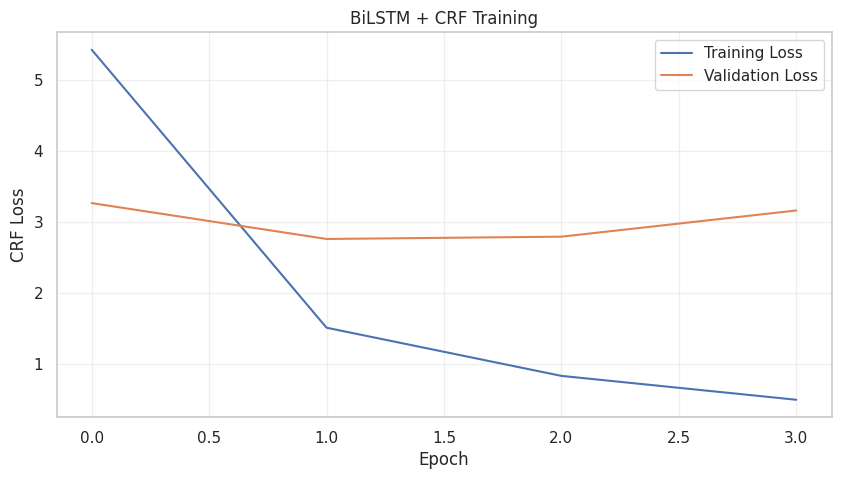

In [54]:
plt.figure(figsize=(10, 5))

plt.plot(crf_history["train_loss"], label="Training Loss")
plt.plot(crf_history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("CRF Loss")
plt.title("BiLSTM + CRF Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [55]:
crf_model.eval()

crf_true_tags = []
crf_predicted_tags = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        predictions = crf_model(inputs)

        for pred_seq, label_seq in zip(
            predictions,
            labels
        ):
            sentence_true = [
                idx2tag[tag_id]
                for tag_id in label_seq.tolist()
                if tag_id != -100
            ]

            sentence_pred = [
                idx2tag[tag_id]
                for tag_id in pred_seq[:len(sentence_true)]
            ]

            crf_true_tags.append(sentence_true)
            crf_predicted_tags.append(sentence_pred)

print("BiLSTM + CRF Test Results")
print("=" * 50)

print("Precision:", round(
    precision_score(crf_true_tags, crf_predicted_tags), 4
))

print("Recall:", round(
    recall_score(crf_true_tags, crf_predicted_tags), 4
))

print("F1-Score:", round(
    f1_score(crf_true_tags, crf_predicted_tags), 4
))

print("\nDetailed Classification Report:")
print(classification_report(
    crf_true_tags,
    crf_predicted_tags
))

BiLSTM + CRF Test Results
Precision: 0.7976
Recall: 0.6218
F1-Score: 0.6988

Detailed Classification Report:
              precision    recall  f1-score   support

         LOC       0.85      0.79      0.82      1630
        MISC       0.72      0.65      0.68       690
         ORG       0.79      0.55      0.65      1639
         PER       0.78      0.50      0.61      1548

   micro avg       0.80      0.62      0.70      5507
   macro avg       0.78      0.62      0.69      5507
weighted avg       0.79      0.62      0.69      5507



In [56]:
comparison = pd.DataFrame([
    {
        "Model": "LSTM + GloVe",
        "Precision": 0.7474,
        "Recall": 0.5847,
        "F1-Score": 0.6561
    },
    {
        "Model": "BiLSTM + GloVe",
        "Precision": 0.7805,
        "Recall": 0.6127,
        "F1-Score": 0.6865
    },
    {
        "Model": "BiLSTM + CRF",
        "Precision": precision_score(crf_true_tags, crf_predicted_tags),
        "Recall": recall_score(crf_true_tags, crf_predicted_tags),
        "F1-Score": f1_score(crf_true_tags, crf_predicted_tags)
    }
])

display(
    comparison.style
    .format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
    .highlight_max(
        subset=["Precision", "Recall", "F1-Score"],
        color="#c8f7dc"
    )
    .set_caption("NER Models Performance Comparison")
)

,Model,Precision,Recall,F1-Score
0,LSTM + GloVe,74.74%,58.47%,65.61%
1,BiLSTM + GloVe,78.05%,61.27%,68.65%
2,BiLSTM + CRF,79.76%,62.18%,69.88%


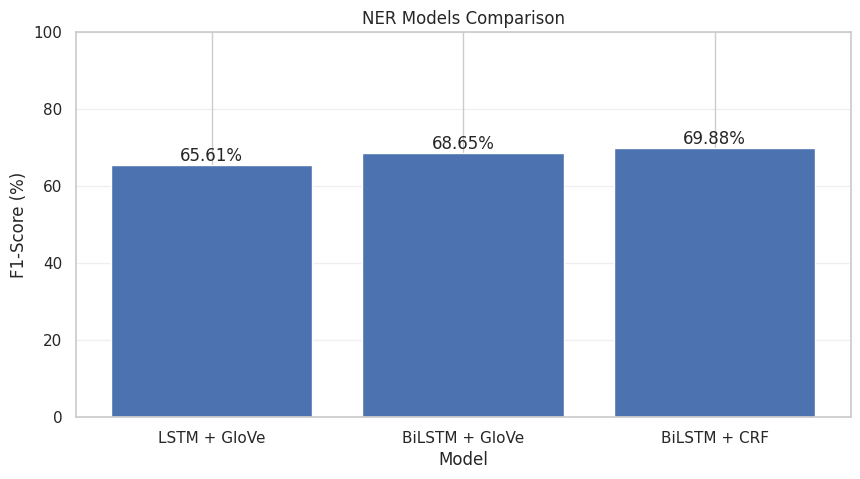

In [57]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison["Model"],
    comparison["F1-Score"] * 100
)

plt.ylabel("F1-Score (%)")
plt.xlabel("Model")
plt.title("NER Models Comparison")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(comparison["F1-Score"]):
    plt.text(
        i,
        value * 100 + 1,
        f"{value:.2%}",
        ha="center"
    )

plt.show()

In [58]:
!pip install -q transformers datasets accelerate seqeval

In [59]:
MODEL_NAME = "bert-base-cased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

bert_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(tag2idx),
    id2label=idx2tag,
    label2id=tag2idx
)

bert_model.to(device)

print("Tokenizer Loaded:", MODEL_NAME)
print("Number of Labels:", len(tag2idx))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i

Tokenizer Loaded: bert-base-cased
Number of Labels: 9


In [60]:
def tokenize_and_align_labels(examples):
    tokenized_inputs = tokenizer(
        examples["tokens"],
        truncation=True,
        is_split_into_words=True,
        max_length=128
    )

    aligned_labels = []

    for i, labels in enumerate(examples["tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)

        previous_word_idx = None
        label_ids = []

        for word_idx in word_ids:
            if word_idx is None:
                label_ids.append(-100)

            elif word_idx != previous_word_idx:
                label_ids.append(tag2idx[labels[word_idx]])

            else:
                label_ids.append(-100)

            previous_word_idx = word_idx

        aligned_labels.append(label_ids)

    tokenized_inputs["labels"] = aligned_labels

    return tokenized_inputs

In [61]:
train_hf = Dataset.from_list(train_data)
valid_hf = Dataset.from_list(valid_data)
test_hf = Dataset.from_list(test_data)

train_tokenized = train_hf.map(
    tokenize_and_align_labels,
    batched=True
)

valid_tokenized = valid_hf.map(
    tokenize_and_align_labels,
    batched=True
)

test_tokenized = test_hf.map(
    tokenize_and_align_labels,
    batched=True
)

print("Train:", len(train_tokenized))
print("Validation:", len(valid_tokenized))
print("Test:", len(test_tokenized))

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

Train: 14041
Validation: 3250
Test: 3453


In [63]:
data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=2)

    true_predictions = []
    true_labels = []

    for prediction, label in zip(predictions, labels):
        sentence_predictions = []
        sentence_labels = []

        for pred_id, label_id in zip(prediction, label):
            if label_id == -100:
                continue

            sentence_predictions.append(idx2tag[int(pred_id)])
            sentence_labels.append(idx2tag[int(label_id)])

        true_predictions.append(sentence_predictions)
        true_labels.append(sentence_labels)

    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions)
    }

In [64]:
training_args = TrainingArguments(
    output_dir="/kaggle/working/bert_ner_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=valid_tokenized,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2)
    ]
)

print("BERT Trainer Ready!")

BERT Trainer Ready!


In [65]:
trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,No log,0.094017,0.912304,0.930593,0.921358
2,0.269078,0.078496,0.933255,0.942217,0.937715
3,0.059810,0.074771,0.936616,0.948450,0.942496


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=1317, training_loss=0.13398112034200263, metrics={'train_runtime': 374.5211, 'train_samples_per_second': 112.472, 'train_steps_per_second': 3.516, 'total_flos': 1161918840783762.0, 'train_loss': 0.13398112034200263, 'epoch': 3.0})

In [66]:
trainer.save_model("/kaggle/working/bert_ner_model")
tokenizer.save_pretrained("/kaggle/working/bert_ner_model")

print("BERT Model Saved Successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT Model Saved Successfully!


In [67]:
bert_results = trainer.predict(test_tokenized)

print("BERT Test Results")
print("=" * 50)

print("Precision:", round(bert_results.metrics["test_precision"], 4))
print("Recall:", round(bert_results.metrics["test_recall"], 4))
print("F1-Score:", round(bert_results.metrics["test_f1"], 4))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


BERT Test Results
Precision: 0.8983
Recall: 0.9137
F1-Score: 0.9059


In [68]:
predictions = np.argmax(bert_results.predictions, axis=2)
labels = bert_results.label_ids

bert_true_tags = []
bert_predicted_tags = []

for prediction, label in zip(predictions, labels):
    sentence_true = []
    sentence_pred = []

    for pred_id, label_id in zip(prediction, label):
        if label_id == -100:
            continue

        sentence_true.append(idx2tag[int(label_id)])
        sentence_pred.append(idx2tag[int(pred_id)])

    bert_true_tags.append(sentence_true)
    bert_predicted_tags.append(sentence_pred)

print(classification_report(
    bert_true_tags,
    bert_predicted_tags
))

              precision    recall  f1-score   support

         LOC       0.94      0.92      0.93      1666
        MISC       0.76      0.81      0.78       702
         ORG       0.86      0.91      0.88      1661
         PER       0.96      0.96      0.96      1615

   micro avg       0.90      0.91      0.91      5644
   macro avg       0.88      0.90      0.89      5644
weighted avg       0.90      0.91      0.91      5644



In [69]:
print(classification_report(
    bert_true_tags,
    bert_predicted_tags,
    digits=4
))

              precision    recall  f1-score   support

         LOC     0.9362    0.9250    0.9306      1666
        MISC     0.7570    0.8077    0.7815       702
         ORG     0.8649    0.9055    0.8847      1661
         PER     0.9614    0.9567    0.9590      1615

   micro avg     0.8983    0.9137    0.9059      5644
   macro avg     0.8799    0.8987    0.8890      5644
weighted avg     0.9001    0.9137    0.9067      5644



In [70]:
comparison = pd.DataFrame([
    {
        "Model": "LSTM + GloVe",
        "Precision": 0.7474,
        "Recall": 0.5847,
        "F1-Score": 0.6561
    },
    {
        "Model": "BiLSTM + GloVe",
        "Precision": 0.7805,
        "Recall": 0.6127,
        "F1-Score": 0.6865
    },
    {
        "Model": "BiLSTM + CRF",
        "Precision": precision_score(crf_true_tags, crf_predicted_tags),
        "Recall": recall_score(crf_true_tags, crf_predicted_tags),
        "F1-Score": f1_score(crf_true_tags, crf_predicted_tags)
    },
    {
        "Model": "BERT",
        "Precision": precision_score(bert_true_tags, bert_predicted_tags),
        "Recall": recall_score(bert_true_tags, bert_predicted_tags),
        "F1-Score": f1_score(bert_true_tags, bert_predicted_tags)
    }
])

display(
    comparison.style
    .format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-Score": "{:.2%}"
    })
    .highlight_max(
        subset=["Precision", "Recall", "F1-Score"],
        color="#c8f7dc"
    )
    .set_caption("NER Models Final Comparison")
)

,Model,Precision,Recall,F1-Score
0,LSTM + GloVe,74.74%,58.47%,65.61%
1,BiLSTM + GloVe,78.05%,61.27%,68.65%
2,BiLSTM + CRF,79.76%,62.18%,69.88%
3,BERT,89.83%,91.37%,90.59%


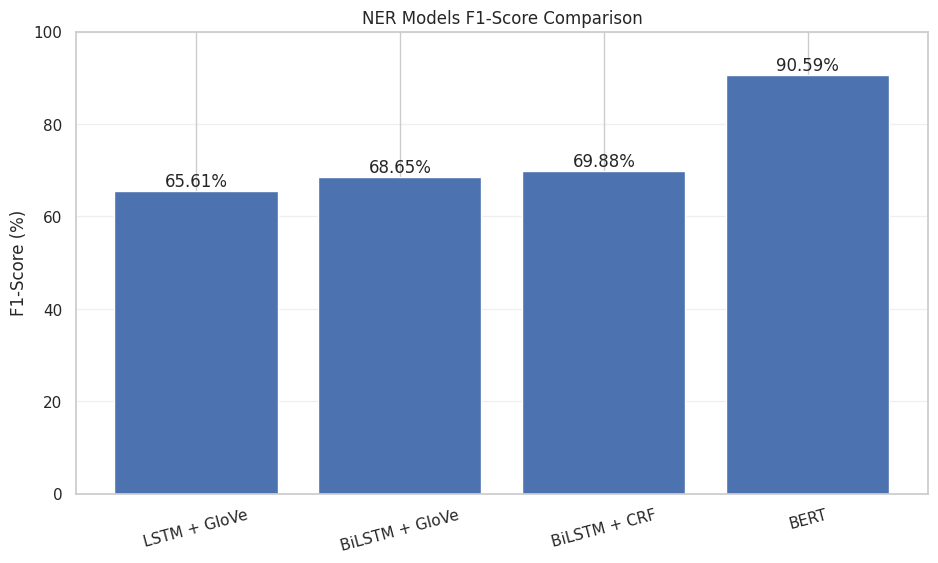

In [71]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    comparison["Model"],
    comparison["F1-Score"] * 100
)

plt.title("NER Models F1-Score Comparison")
plt.ylabel("F1-Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, comparison["F1-Score"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2%}",
        ha="center"
    )

plt.show()

In [72]:
"""
Named Entity Recognition (CoNLL-2003) - Gradio demo
Fine-tuned BERT only. Inference-only: no training happens here.

Run:  python app.py
"""
import html
import os
from pathlib import Path

import gradio as gr
import torch
from transformers import AutoModelForTokenClassification, AutoTokenizer

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

# --------------------------------------------------------------------------
# Config
# --------------------------------------------------------------------------
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:  # running inside a notebook (Kaggle / Colab / Jupyter)
    BASE_DIR = Path.cwd()

# Override with env var, e.g. on Kaggle: /kaggle/input/<dataset>/bert_ner_model
MODEL_DIR = Path(os.environ.get("MODEL_DIR", BASE_DIR / "bert_ner_model"))
MAX_LEN = 128      # max tokens per window (incl. [CLS] / [SEP])
STRIDE = 32        # token overlap between consecutive windows (long text)
BATCH_SIZE = 16    # windows per forward pass

COLORS = {  # type -> (main color, soft background)
    "PER": ("#2563eb", "rgba(37, 99, 235, 0.18)"),    # blue
    "ORG": ("#16a34a", "rgba(22, 163, 74, 0.18)"),    # green
    "LOC": ("#dc2626", "rgba(220, 38, 38, 0.18)"),    # red
    "MISC": ("#9333ea", "rgba(147, 51, 234, 0.18)"),  # purple
}
FALLBACK = ("#6b7280", "rgba(107, 114, 128, 0.18)")
FULL_NAMES = {"PER": "Person", "ORG": "Organization", "LOC": "Location", "MISC": "Miscellaneous"}

# --------------------------------------------------------------------------
# Model loading
# --------------------------------------------------------------------------
if not MODEL_DIR.exists():
    raise FileNotFoundError(
        f"Model directory not found: {MODEL_DIR}\n"
        "Put the fine-tuned model in a folder named 'bert_ner_model' next to app.py "
        "or set the MODEL_DIR environment variable."
    )

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, use_fast=True)  # fast tokenizer => offset_mapping
if not tokenizer.is_fast:
    raise RuntimeError("A fast tokenizer is required for offset_mapping.")
model = AutoModelForTokenClassification.from_pretrained(MODEL_DIR).to(DEVICE)
model.eval()
ID2LABEL = {int(k): v for k, v in model.config.id2label.items()}
print(f"Loaded model from {MODEL_DIR} on {DEVICE} | labels: {ID2LABEL}")


# --------------------------------------------------------------------------
# Inference
# --------------------------------------------------------------------------
@torch.no_grad()
def predict_words(text: str):
    """
    Returns a list of word-level predictions sorted by position:
    dict(start, end, label, conf) where start/end are character offsets in `text`.
    Long texts are split into overlapping 128-token windows (sliding window);
    overlapping predictions are resolved by keeping the one furthest from a window edge.
    """
    enc = tokenizer(
        text,
        truncation=True,
        max_length=MAX_LEN,
        stride=STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        return_special_tokens_mask=True,
        padding=True,
        return_tensors="pt",
    )
    n_windows = enc["input_ids"].shape[0]
    word_ids_all = [enc.word_ids(i) for i in range(n_windows)]
    offsets_all = enc.pop("offset_mapping").tolist()
    special_all = enc.pop("special_tokens_mask").tolist()
    enc.pop("overflow_to_sample_mapping", None)

    # ---- forward pass (batched) ----
    preds, confs = [], []
    for b in range(0, n_windows, BATCH_SIZE):
        batch = {k: v[b:b + BATCH_SIZE].to(DEVICE) for k, v in enc.items()}
        probs = torch.softmax(model(**batch).logits, dim=-1)
        conf, pred = probs.max(dim=-1)
        preds.extend(pred.cpu().tolist())
        confs.extend(conf.cpu().tolist())

    # ---- subword -> word reconstruction ----
    best = {}  # word start char -> (margin, conf, record)
    for w in range(n_windows):
        real = [i for i, s in enumerate(special_all[w]) if s == 0]
        n_real = len(real)
        words, cur, prev_wid = [], None, None
        for pos, i in enumerate(real):
            wid = word_ids_all[w][i]
            tok = tokenizer.convert_ids_to_tokens(enc["input_ids"][w][i].item())
            start, end = offsets_all[w][i]
            if wid is not None and wid == prev_wid and cur is not None:
                cur["end"] = end            # continuation subword: extend the span
                cur["last"] = pos
            else:
                if pos == 0 and w > 0 and tok.startswith("##"):
                    prev_wid, cur = wid, None   # window starts mid-word: skip (covered by previous window)
                    continue
                cur = {"start": start, "end": end, "first": pos, "last": pos,
                       "label": ID2LABEL[preds[w][i]], "conf": confs[w][i]}  # label from FIRST subword
                words.append(cur)
            prev_wid = wid
        for c in words:
            margin = min(c["first"], n_real - 1 - c["last"])
            key = c["start"]
            if key not in best or (margin, c["conf"]) > best[key][:2]:
                best[key] = (margin, c["conf"], c)

    return [
        {"start": c["start"], "end": c["end"], "label": c["label"], "conf": c["conf"]}
        for _, _, c in (best[k] for k in sorted(best))
    ]


def group_entities(text: str, words):
    """Merge B-/I- word predictions into entities using character offsets."""
    entities, cur = [], None
    for wd in words:
        label = wd["label"]
        if label == "O":
            tag, etype = "O", None
        else:
            tag, _, etype = label.partition("-")
        continues = cur is not None and tag == "I" and etype == cur["type"]
        if continues:
            cur["end"] = wd["end"]
            cur["confs"].append(wd["conf"])
        else:
            if cur:
                entities.append(cur)
            cur = None
            if tag in ("B", "I"):  # a stray I- is treated as the start of an entity
                cur = {"type": etype, "start": wd["start"], "end": wd["end"], "confs": [wd["conf"]]}
    if cur:
        entities.append(cur)
    for e in entities:
        e["text"] = text[e["start"]:e["end"]]  # original text, punctuation preserved
        e["conf"] = sum(e["confs"]) / len(e["confs"])
    return entities


# --------------------------------------------------------------------------
# Rendering
# --------------------------------------------------------------------------
CSS = """
.ner-box {white-space: pre-wrap; word-wrap: break-word; line-height: 2.4; font-size: 17px;
          padding: 18px 20px; border: 1px solid rgba(128,128,128,.35); border-radius: 12px;}
.ent {padding: 2px 6px; margin: 0 1px; border-radius: 6px; border-bottom: 2px solid var(--c);
      background: var(--bg);}
.ent .tag {font-size: 10px; font-weight: 700; color: #fff; background: var(--c); border-radius: 4px;
           padding: 1px 5px; margin-left: 6px; vertical-align: middle; letter-spacing: .5px;}
.legend {display: flex; flex-wrap: wrap; gap: 10px; margin: 6px 0 2px;}
.legend-item {display: flex; align-items: center; gap: 8px; padding: 6px 12px; border-radius: 999px;
              border: 1px solid rgba(128,128,128,.35); font-size: 14px;}
.dot {width: 12px; height: 12px; border-radius: 50%;}
.stats {opacity: .8; font-size: 14px; margin-top: 8px;}
"""


def legend_html():
    items = "".join(
        f'<div class="legend-item"><span class="dot" style="background:{c}"></span>'
        f"<b>{t}</b> &mdash; {FULL_NAMES[t]}</div>"
        for t, (c, _) in COLORS.items()
    )
    return f'<div class="legend">{items}</div>'


def highlight_html(text: str, entities):
    parts, cursor = [], 0
    for e in entities:
        color, bg = COLORS.get(e["type"], FALLBACK)
        parts.append(html.escape(text[cursor:e["start"]]))
        parts.append(
            f'<span class="ent" style="--c:{color};--bg:{bg}">{html.escape(e["text"])}'
            f'<span class="tag">{html.escape(e["type"])}</span></span>'
        )
        cursor = e["end"]
    parts.append(html.escape(text[cursor:]))
    return f'<div class="ner-box">{"".join(parts)}</div>'


def analyze(text: str):
    if not text or not text.strip():
        return ('<div class="ner-box" style="opacity:.6">Please enter some English text.</div>', [], "")
    entities = group_entities(text, predict_words(text))
    table = [
        [i + 1, e["text"], e["type"], FULL_NAMES.get(e["type"], e["type"]),
         f'{e["conf"]:.1%}', f'{e["start"]}-{e["end"]}']
        for i, e in enumerate(entities)
    ]
    counts = {t: sum(e["type"] == t for e in entities) for t in COLORS}
    stats = (f'<div class="stats">{len(entities)} entities found &nbsp;|&nbsp; '
             + " &nbsp;|&nbsp; ".join(f"{t}: {n}" for t, n in counts.items()) + "</div>")
    return highlight_html(text, entities), table, stats


# --------------------------------------------------------------------------
# UI
# --------------------------------------------------------------------------
EXAMPLES = [
    ["Barack Obama visited Microsoft headquarters in Seattle, Washington, and met Satya Nadella on Monday."],
    ["Real Madrid beat Bayern Munich 2-1 at the Santiago Bernabeu, and Karim Benzema scored twice."],
    ["The European Union and the United Nations criticised Russia, while Germany's Angela Merkel called for talks in Geneva."],
    ["Apple CEO Tim Cook said the new iPhone will launch in Japan, India and Egypt. Cook later flew from Cairo to London."],
]

with gr.Blocks(title="BERT Named Entity Recognition", css=CSS, theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        "# 🔎 Named Entity Recognition\n"
        "Fine-tuned **BERT** on CoNLL-2003 &middot; detects **PER, ORG, LOC, MISC** in English text."
    )
    with gr.Row():
        with gr.Column(scale=1):
            inp = gr.Textbox(label="Input text", lines=9, placeholder="Paste or type English text here...")
            with gr.Row():
                btn = gr.Button("Analyze", variant="primary")
                clr = gr.Button("Clear")
            gr.Examples(EXAMPLES, inputs=inp, label="Examples")
        with gr.Column(scale=1):
            gr.Markdown("### Highlighted text")
            out_html = gr.HTML()
            gr.HTML(legend_html())
            out_stats = gr.HTML()
    gr.Markdown("### Extracted entities")
    out_table = gr.Dataframe(
        headers=["#", "Entity", "Type", "Category", "Confidence", "Char span"],
        datatype=["number", "str", "str", "str", "str", "str"],
        interactive=False, wrap=True,
    )

    btn.click(analyze, inp, [out_html, out_table, out_stats])
    inp.submit(analyze, inp, [out_html, out_table, out_stats])
    clr.click(lambda: ("", "", [], ""), None, [inp, out_html, out_table, out_stats])

if __name__ == "__main__":
    on_kaggle = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
    demo.launch(share=on_kaggle)  # Kaggle needs a public share link

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loaded model from /kaggle/working/bert_ner_model on cuda | labels: {0: 'B-LOC', 1: 'B-MISC', 2: 'B-ORG', 3: 'B-PER', 4: 'I-LOC', 5: 'I-MISC', 6: 'I-ORG', 7: 'I-PER', 8: 'O'}


/tmp/ipykernel_49/379342890.py:223: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="BERT Named Entity Recognition", css=CSS, theme=gr.themes.Soft()) as demo:


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://966bdefebcaa5f983f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
